In [1]:
import numpy as np
import h2py
import pickle
import matplotlib.pyplot as plt
import scipy
import pandas
import demes

In [4]:
# Load empirical data and sample 500 bootstrap sets
data = {}
for c in range(1, 23):
    fname = f"../empirical_statistics/outputs/stats_accessible_1e-4M_ccds_flank_bherer_chr_{c}.pkl"
    with open(fname, "rb") as fin:
        cdata = pickle.load(fin)
    for key in cdata:
        data[key] = cdata[key]
print(len(data))
boot_samples = h2py.parsing.get_bootstrap_replicates(data)
output = {"samples": boot_samples, "pops": data[next(iter(data))]["pops"]}

with open("accessible_1e-4M_ccds_flank_bherer_boot_samples.pkl", "wb") as fout:
    pickle.dump(output, fout)

561


In [5]:
# Load simulated/parametric bootstap replicates
sim_samples = []
for i in range(500):
    fname = f"simulation_outputs/bherer_full_rep{i}_boot_h2.pkl"
    with open(fname, "rb") as fin:
        data = pickle.load(fin)
    sim_samples.append(data["means"])
sim_samples = np.array(sim_samples)
print(sim_samples.shape)
pops = data["pops"]
print(pops)

# Load empirical bootstrap
with open("accessible_1e-4M_ccds_flank_bherer_boot_samples.pkl", "rb") as fin:
    boot_data = pickle.load(fin)
boot_samples = boot_data["samples"]
boot_samples = [h2py.parsing._subset_means(m, boot_data["pops"], pops) for m in boot_samples]
boot_samples = np.array(boot_samples)[:500]
boot_samples *= (1.12212e-08) ** 2
print(boot_samples.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'simulation_outputs/bherer_full_rep0_boot_h2.pkl'

(array([  5.,  18.,  56., 101., 125.,  99.,  62.,  26.,   7.,   1.]),
 array([1.85418428e-06, 1.87748681e-06, 1.90078934e-06, 1.92409187e-06,
        1.94739440e-06, 1.97069692e-06, 1.99399945e-06, 2.01730198e-06,
        2.04060451e-06, 2.06390703e-06, 2.08720956e-06]),
 <BarContainer object of 10 artists>)

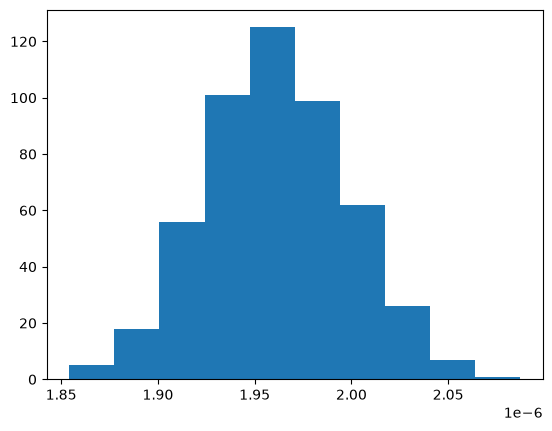

In [18]:
plt.hist(means[:, 1, -1])

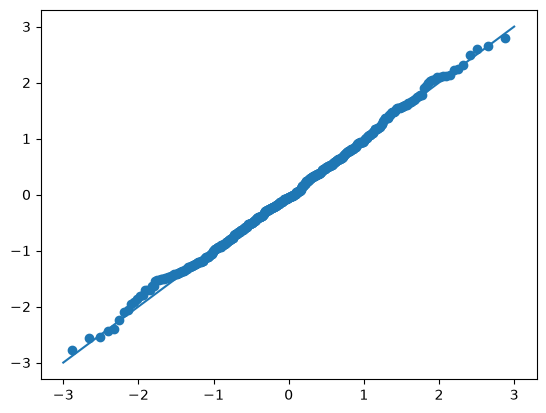

In [34]:
x = means[:, 0, -1]
norm_x = np.sort((x - np.mean(x)) / np.std(x))
quantiles = scipy.stats.norm.ppf(np.linspace(0, 1, len(norm_x)))
plt.plot([-3, 3], [-3, 3])
plt.scatter(quantiles, norm_x)

(array([[  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   6., 494.],
        [500.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.]]),
 array([1.17670893e-06, 1.02578799e+09, 2.05157598e+09, 3.07736398e+09,
        4.10315197e+09, 5.12893996e+09, 6.15472795e+09, 7.18051594e+09,
        8.20630393e+09, 9.23209193e+09, 1.02578799e+10]),
 <a list of 2 list[Polygon] objects>)

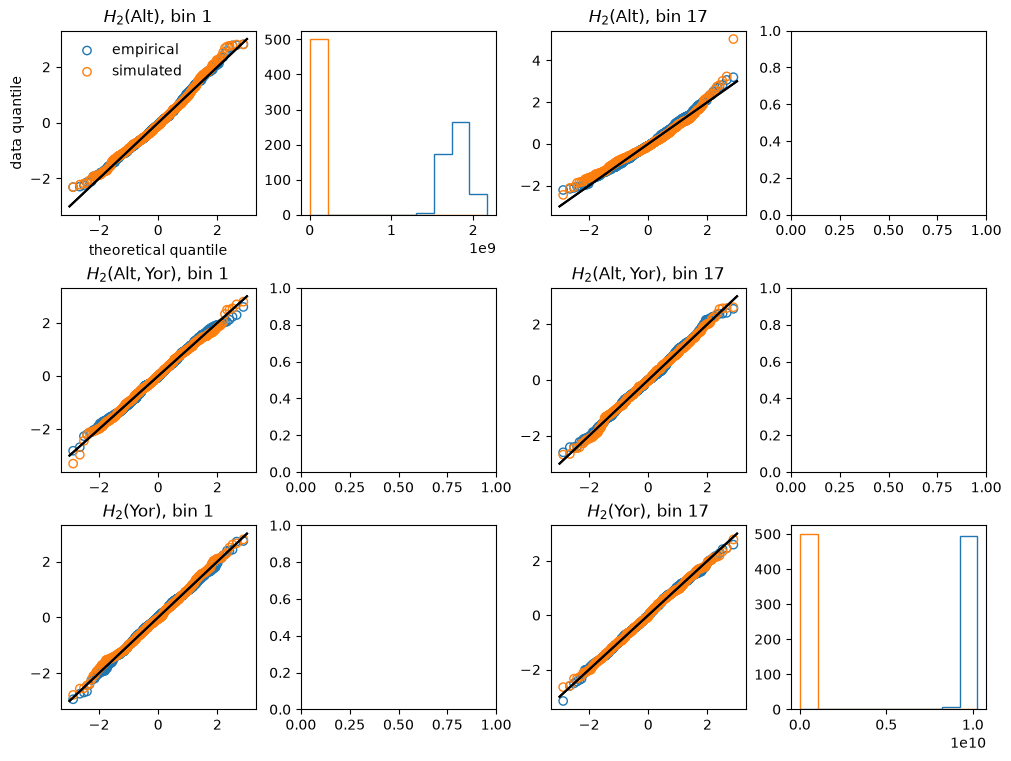

In [60]:
def qq_plot(ax, data, color, label=None):
    norm_data = np.sort((data - np.mean(data)) / np.std(data))
    quantiles = scipy.stats.norm.ppf(np.linspace(0, 1, len(norm_data)))
    ax.plot([-3, 3], [-3, 3], color="black")
    ax.scatter(quantiles, norm_data, color=color, label=label, facecolor="none")
    return


stat_names = h2py.utils._h2_names(len(pops))

fig, axs = plt.subplots(3, 4, figsize=(10, 7.5), layout="constrained")

alt_idx = pops.index("Altai")
idx = stat_names.index(f"H2_{alt_idx}_{alt_idx}")
qq_plot(axs[0, 0], boot_samples[:, 0, idx], "tab:blue", label="empirical")
qq_plot(axs[0, 0], sim_samples[:, 0, idx], "tab:orange", label="simulated")
axs[0, 0].legend(framealpha=0)
axs[0, 0].set_title(r"$H_2(\text{Alt})$, bin 1")
axs[0, 0].set_xlabel("theoretical quantile")
axs[0, 0].set_ylabel("data quantile")

axs[0, 1].hist([boot_samples[:, 0, idx], sim_samples[:, 0, idx]], 
               histtype="step")

qq_plot(axs[0, 2], boot_samples[:, -2, idx], "tab:blue")
qq_plot(axs[0, 2], sim_samples[:, -2, idx], "tab:orange")
axs[0, 2].set_title(r"$H_2(\text{Alt})$, bin 17")


yor_idx = pops.index("Yoruba1")
idx = stat_names.index(f"H2_{alt_idx}_{yor_idx}")
qq_plot(axs[1, 0], boot_samples[:, 0, idx], "tab:blue")
qq_plot(axs[1, 0], sim_samples[:, 0, idx], "tab:orange")
axs[1, 0].set_title(r"$H_2(\text{Alt}, \text{Yor})$, bin 1")

qq_plot(axs[1, 2], boot_samples[:, -2, idx], "tab:blue")
qq_plot(axs[1, 2], sim_samples[:, -2, idx], "tab:orange")
axs[1, 2].set_title(r"$H_2(\text{Alt}, \text{Yor})$, bin 17")


idx = stat_names.index(f"H2_{yor_idx}_{yor_idx}")
qq_plot(axs[2, 0], boot_samples[:, 0, idx], "tab:blue")
qq_plot(axs[2, 0], sim_samples[:, 0, idx], "tab:orange")
axs[2, 0].set_title(r"$H_2(\text{Yor})$, bin 1")

qq_plot(axs[2, 2], boot_samples[:, -2, idx], "tab:blue")
qq_plot(axs[2, 2], sim_samples[:, -2, idx], "tab:orange")
axs[2, 2].set_title(r"$H_2(\text{Yor})$, bin 17")

axs[2, 3].hist([boot_samples[:, -2, idx], sim_samples[:, -2, idx]], 
               histtype="step")